# 🫁 Chest X-Ray Pneumonia Classification with CNN
### Beginner Deep Learning | Image Classification

> Can a small Convolutional Neural Network (CNN) learn to distinguish the `NORMAL` and `PNEUMONIA` labels in chest X-ray images? We load the images, train a CNN, and inspect its test predictions.

**Dataset:** [Chest X-Ray Images (Pneumonia) on Kaggle](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia)  
**Problem:** Image Classification · **Classes:** `NORMAL` / `PNEUMONIA`

In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/__MACOSX/._chest_xray
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/._.DS_Store
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/._test
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/._train
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/test/._.DS_Store
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/test/._NORMAL
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/test/._PNEUMONIA
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/test/NORMAL/._IM-0001-0001.jpeg
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/test/NORMAL/._IM-0003-0001.jpeg
/kaggle/input/datasets

In [2]:
data_dir = '/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray'

print(os.listdir(data_dir))

['__MACOSX', 'chest_xray', 'test', 'train', 'val']


### Load Images

In [3]:
import tensorflow as tf

In [14]:
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

In [15]:
load = tf.keras.utils.image_dataset_from_directory

train_ds = load(data_dir + '/train', image_size=(128,128), batch_size=32)
val_ds = load(data_dir + '/val', image_size=(128,128), batch_size=32, shuffle=False)
test_ds = load(data_dir + '/test', image_size=(128,128), batch_size=32, shuffle=False)

print(train_ds.class_names)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
['NORMAL', 'PNEUMONIA']


### Sample Chest X-Ray Images

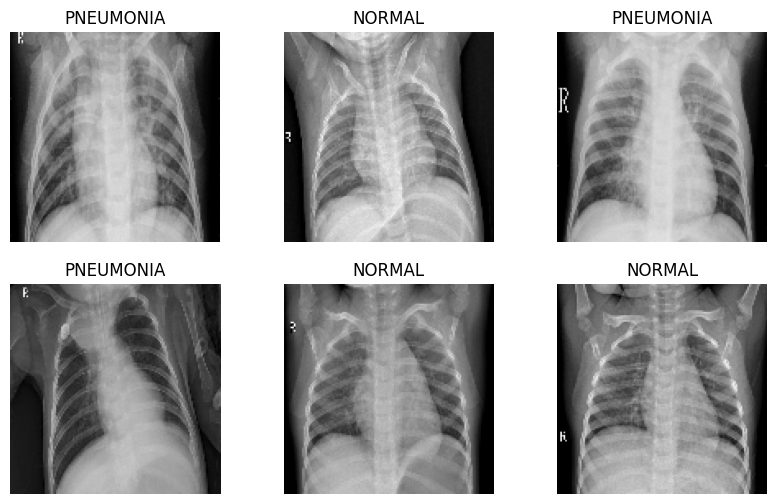

In [5]:
import matplotlib.pyplot as plt

class_names = train_ds.class_names

plt.figure(figsize=(10, 6))

for images, labels in train_ds.take(1):
    for i in range(6):
        plt.subplot(2, 3, i+1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[int(labels[i])])
        plt.axis('off')

plt.show()

### Build the CNN Model

In [6]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128,128,3)),
    tf.keras.layers.Rescaling(1./255),
    tf.keras.layers.Conv2D(16, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

In [7]:
history = model.fit(train_ds, validation_data=val_ds, epochs=5)

Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 163s 989ms/step - accuracy: 0.8397 - loss: 0.3586 - val_accuracy: 0.7500 - val_loss: 0.5491
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 44s 265ms/step - accuracy: 0.9519 - loss: 0.2232 - val_accuracy: 0.6875 - val_loss: 0.6433
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 42s 256ms/step - accuracy: 0.9601 - loss: 0.1999 - val_accuracy: 0.6875 - val_loss: 0.5798
Epoch 4/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 42s 256ms/step - accuracy: 0.9641 - loss: 0.1798 - val_accuracy: 0.6875 - val_loss: 0.5667
Epoch 5/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 42s 255ms/step - accuracy: 0.9695 - loss: 0.1094 - val_accuracy: 0.6875 - val_loss: 0.6678


In [13]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 28800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       921,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,780,261 (10.61 MB)

 Trainable params: 926,753 (3.54 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,853,508 (7.07 MB)

### Training vs. Validation Accuracy

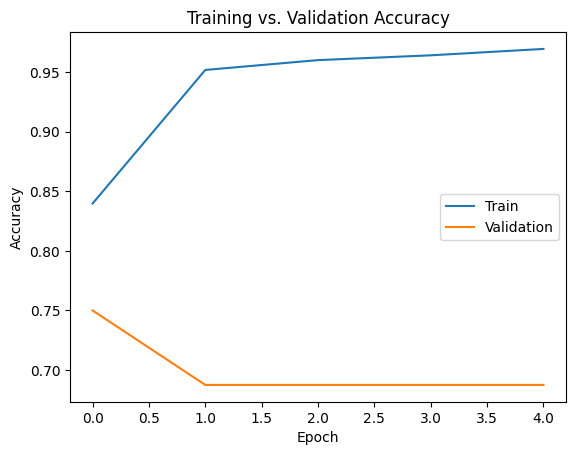

In [8]:
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')

plt.title('Training vs. Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

### Evaluate the Model

In [9]:
loss, accuracy = model.evaluate(test_ds)

print('Test Accuracy:', round(accuracy, 3))
print('Test Loss:', round(loss, 3))

20/20 ━━━━━━━━━━━━━━━━━━━━ 17s 807ms/step - accuracy: 0.7099 - loss: 1.3825
Test Accuracy: 0.71
Test Loss: 1.382


In [10]:
accuracy

0.7099359035491943

#### Classification Report

In [11]:
from sklearn.metrics import classification_report

y_true = np.concatenate([y.numpy() for x, y in test_ds])
y_pred = (model.predict(test_ds).ravel() >= 0.5).astype(int)

print(classification_report(y_true, y_pred, target_names=class_names))

20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 114ms/step
              precision    recall  f1-score   support

      NORMAL       0.98      0.23      0.37       234
   PNEUMONIA       0.68      1.00      0.81       390

    accuracy                           0.71       624
   macro avg       0.83      0.61      0.59       624
weighted avg       0.80      0.71      0.65       624



#### Confusion Matrix

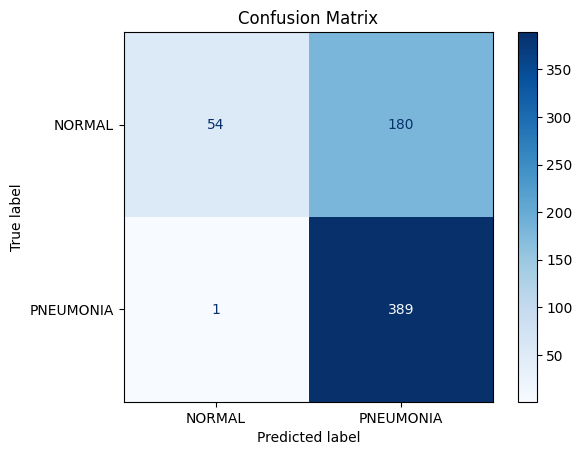

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred,
    display_labels=class_names,
    cmap='Blues'
)

plt.title('Confusion Matrix')
plt.show()

## Results and Conclusion

The CNN achieved **70.99% test accuracy**. The model identified almost all PNEUMONIA images correctly but struggled with NORMAL images, showing that its performance is not balanced across both classes..

- **Training Images:** 5,216
- **Test Images:** 624
- **Test Accuracy:** 70.99%
- **Test Loss:** 1.382
- **Training Accuracy:** Approximately 97%
- **PNEUMONIA Recall:** 99.74%
- **NORMAL Recall:** 23.08%

**Limitations**

- **Class Imbalance:** The training dataset contains significantly more PNEUMONIA than NORMAL images. This may cause the model to favor PNEUMONIA predictions
- **Small Validation Set:** Only 16 images are available for validation, making the results less reliable
- **Possible Overfitting:** The large gap between training and test accuracy suggests that the model may have learned patterns too specific to the training images
- **Data Diversity:** Differences in image quality, brightness, or X-ray equipment may affect performance on new images

The goal is not just to learn the training images, but to make accurate predictions on new, unseen images. This is called **generalization**. More training epochs do not always lead to better results.

This project highlights the importance of balanced and diverse training data. The CNN is useful for learning image classification.